## Домашнее задание
### школа аналитиков HH.RU · теория вероятностей
##### Автор: Иващенко Юлия

### 2. Симуляции в Python

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

#### Задание 2.1. Нормальная выборка

Теоретическое среднее: 40
Выборочное среднее: 39.841
Теоретическое стандартное отклонение: 8
Выборочное стандартное отклонение: 7.996


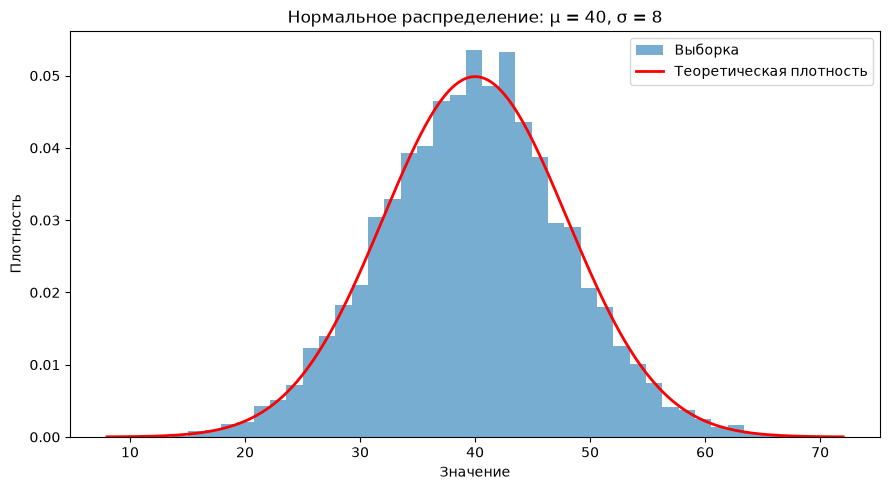

In [3]:
mu = 40
sigma = 8
sample_size = 5000

normal_sample = rng.normal(
    loc=mu,
    scale=sigma,
    size=sample_size
)

print(f"Теоретическое среднее: {mu}")
print(f"Выборочное среднее: {normal_sample.mean():.3f}")
print(f"Теоретическое стандартное отклонение: {sigma}")
print(
    "Выборочное стандартное отклонение: "
    f"{normal_sample.std(ddof=1):.3f}"
)

x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)

plt.figure(figsize=(9, 5))
plt.hist(
    normal_sample,
    bins=40,
    density=True,
    alpha=0.6,
    label="Выборка"
)
plt.plot(
    x,
    stats.norm.pdf(x, loc=mu, scale=sigma),
    color="red",
    linewidth=2,
    label="Теоретическая плотность"
)
plt.title("Нормальное распределение: μ = 40, σ = 8")
plt.xlabel("Значение")
plt.ylabel("Плотность")
plt.legend()
plt.tight_layout()
plt.show()

Гистограмма выборки имеет форму колокола и близка к теоретической плотности нормального распределения. Выборочные среднее и стандартное отклонение близки к заданным значениям 40 и 8. Есть небольшие расхождения из-за случайности

#### Задание 2.2. Биномиальная выборк

Теоретическое среднее: 40.000
Выборочное среднее: 39.900
Теоретическое стандартное отклонение: 6.197
Выборочное стандартное отклонение: 6.202


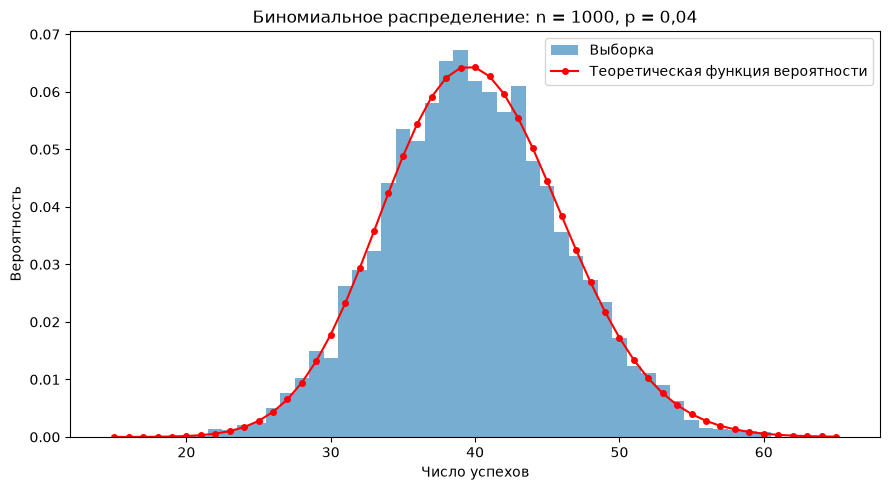

In [4]:
n = 1000
p = 0.04
sample_size = 5000

binomial_sample = rng.binomial(n=n, p=p, size=sample_size)

theoretical_mean = n * p
theoretical_std = np.sqrt(n * p * (1 - p))

print(f"Теоретическое среднее: {theoretical_mean:.3f}")
print(f"Выборочное среднее: {binomial_sample.mean():.3f}")
print(
    "Теоретическое стандартное отклонение: "
    f"{theoretical_std:.3f}"
)
print(
    "Выборочное стандартное отклонение: "
    f"{binomial_sample.std(ddof=1):.3f}"
)

# Целые значения для отображения функции вероятности
k_min = max(
    0,
    min(binomial_sample.min(),
        int(np.floor(theoretical_mean - 4 * theoretical_std)))
)
k_max = min(
    n,
    max(binomial_sample.max(),
        int(np.ceil(theoretical_mean + 4 * theoretical_std)))
)
k = np.arange(k_min, k_max + 1)

bins = np.arange(k_min - 0.5, k_max + 1.5, 1)

plt.figure(figsize=(9, 5))
plt.hist(
    binomial_sample,
    bins=bins,
    density=True,
    alpha=0.6,
    label="Выборка"
)
plt.plot(
    k,
    stats.binom.pmf(k, n=n, p=p),
    "o-",
    color="red",
    markersize=4,
    label="Теоретическая функция вероятности"
)
plt.title("Биномиальное распределение: n = 1000, p = 0,04")
plt.xlabel("Число успехов")
plt.ylabel("Вероятность")
plt.legend()
plt.tight_layout()
plt.show()

Выборочные среднее и стандартное отклонение близки к теоретическим значениям 40 и 6,197. Высоты столбиков гистограммы примерно совпадают со значениями теоретической функции вероятности. Распределение дискретное, поэтому для сравнения используется функция вероятности pmf, а столбики гистограммы имеют ширину 1

#### Задание 2.3. ЦПТ на экспоненциальном распределении

Теоретическое среднее: 10.000
Среднее полученных средних: 9.993
Теоретическое стандартное отклонение средних: 0.447
Выборочное стандартное отклонение средних: 0.447


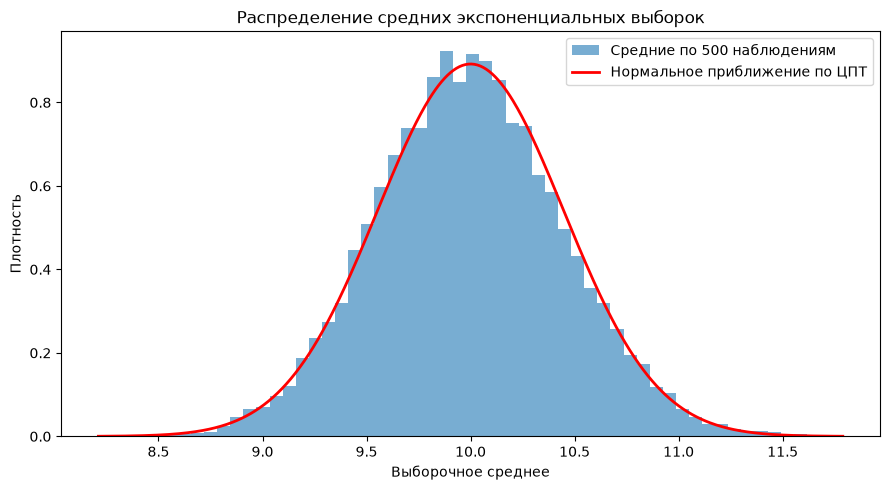

In [5]:
scale = 10
sample_size = 500
n_repeats = 10_000

sample_means = np.array([
    rng.exponential(scale=scale, size=sample_size).mean()
    for _ in range(n_repeats)
])

theoretical_mean = scale
theoretical_se = scale / np.sqrt(sample_size)

print(f"Теоретическое среднее: {theoretical_mean:.3f}")
print(f"Среднее полученных средних: {sample_means.mean():.3f}")
print(
    "Теоретическое стандартное отклонение средних: "
    f"{theoretical_se:.3f}"
)
print(
    "Выборочное стандартное отклонение средних: "
    f"{sample_means.std(ddof=1):.3f}"
)

x = np.linspace(
    min(sample_means.min(), theoretical_mean - 4 * theoretical_se),
    max(sample_means.max(), theoretical_mean + 4 * theoretical_se),
    500
)

plt.figure(figsize=(9, 5))
plt.hist(
    sample_means,
    bins=50,
    density=True,
    alpha=0.6,
    label="Средние по 500 наблюдениям"
)
plt.plot(
    x,
    stats.norm.pdf(
        x,
        loc=theoretical_mean,
        scale=theoretical_se
    ),
    color="red",
    linewidth=2,
    label="Нормальное приближение по ЦПТ"
)
plt.title("Распределение средних экспоненциальных выборок")
plt.xlabel("Выборочное среднее")
plt.ylabel("Плотность")
plt.legend()
plt.tight_layout()
plt.show()

Гистограмма выборочных средних близка к колоколу, хотя исходное экспоненциальное распределение асимметрично. Это согласуется с центральной предельной теоремой, где среднее большого числа независимых одинаково распределённых величин с конечной дисперсией имеет приблизительно нормальное распределение. Средние сосредоточены около 10, а их стандартное отклонение близко к 10 / ((500)^0,5)

### 3. Мини-кейс про кнопку

#### Задание 3.1. Посчитать по формуле
В каждой группе по 5000 соискателей. Выборочные конверсии:

p₁ = 155 / 5000 = 0,031

p₂ = 170 / 5000 = 0,034

Разница конверсий:

∆ = p₂ − p₁ = 0,003

Стандартная ошибка оценки конверсии:

SE = (p(1 − p) / n)^0,5

SE1 = (0,031 · 0,969 / 5000)^0,5 = 0,245 п.п

SE2 = (0,034 · 0,966 / 5000)^0,5 = 0,256 п.п

Поскольку группы независимы

SE(Δ) = (SE1^2 + SE2^2)^0,5 = 0,355 п. п

Наблюдаемая разница 0,3 п.п, это примерно 0,85 стандартной ошибки разницы

По этим данным пока недостаточно оснований утверждать, что новая кнопка повышает конверсию

### Задание 3.2. Проверить симуляцией

Предположим, что кнопка не влияет на конверсию. Общую вероятность отклика оценим по объединённым данным:

p = (155 + 170) / (5000 + 5000) = 0,0325

Общая конверсия: 3.25%
Наблюдаемая разница: 0.300 п.п.
Доля симуляций с разницей ≥ 0,3 п.п.: 20.52%
Доля симуляций с разницей по модулю ≥ 0,3 п.п.: 41.22%


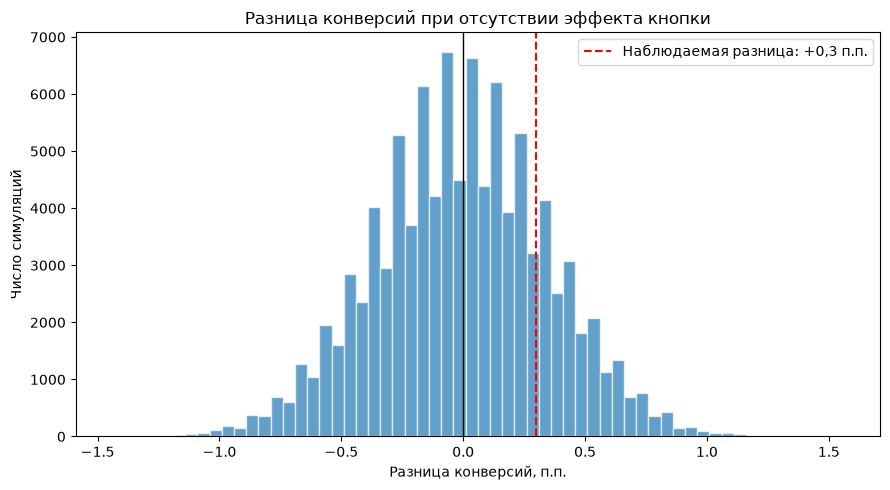

In [6]:
n = 5000
n_simulations = 100_000
p_common = (155 + 170) / (5000 + 5000)
observed_diff = (170 - 155) / n

old_responses = rng.binomial(n, p_common, size=n_simulations)
new_responses = rng.binomial(n, p_common, size=n_simulations)

response_diffs = new_responses - old_responses
conversion_diffs = response_diffs / n

share_positive = np.mean(response_diffs >= 15)

share_two_sided = np.mean(np.abs(response_diffs) >= 15)

print(f"Общая конверсия: {p_common:.2%}")
print(f"Наблюдаемая разница: {observed_diff * 100:.3f} п.п.")
print(
    "Доля симуляций с разницей ≥ 0,3 п.п.: "
    f"{share_positive:.2%}"
)
print(
    "Доля симуляций с разницей по модулю ≥ 0,3 п.п.: "
    f"{share_two_sided:.2%}"
)

plt.figure(figsize=(9, 5))
plt.hist(
    conversion_diffs * 100,
    bins=60,
    alpha=0.7,
    edgecolor="white"
)
plt.axvline(
    observed_diff * 100,
    color="red",
    linestyle="--",
    label="Наблюдаемая разница: +0,3 п.п."
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Разница конверсий при отсутствии эффекта кнопки")
plt.xlabel("Разница конверсий, п.п.")
plt.ylabel("Число симуляций")
plt.legend()
plt.tight_layout()
plt.show()

Распределение разниц конверсий сосредоточено около нуля. Даже при одинаковой вероятности отклика в обеих группах разница не меньше наблюдаемой возникает достаточно часто. Поэтому результат совместим со случайным шумом: убедительных свидетельств эффекта новой кнопки нет, хотя это не доказывает полного отсутствия эффекта

### Задание 3.3. Выбросы во времени сессий

In [7]:
sessions = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

mean = sessions.mean()
std = sessions.std(ddof=1)

lower_3s = mean - 3 * std
upper_3s = mean + 3 * std

outliers_3s = sessions[
    (sessions < lower_3s) | (sessions > upper_3s)
]

q25, q75 = np.percentile(sessions, [25, 75])
iqr = q75 - q25

lower_iqr = q25 - 1.5 * iqr
upper_iqr = q75 + 1.5 * iqr

outliers_iqr = sessions[
    (sessions < lower_iqr) | (sessions > upper_iqr)
]

print(f"Среднее: {mean:.2f} мин.")
print(f"Стандартное отклонение: {std:.2f} мин.")
print(f"Границы трёх сигм: [{lower_3s:.2f}; {upper_3s:.2f}]")
print("Выбросы по трём сигмам:", outliers_3s.tolist())

print(f"\n25-й перцентиль: {q25:.2f} мин.")
print(f"75-й перцентиль: {q75:.2f} мин.")
print(f"Межквартильный размах: {iqr:.2f} мин.")
print(f"Границы Тьюки: [{lower_iqr:.2f}; {upper_iqr:.2f}]")
print("Выбросы по правилу Тьюки:", outliers_iqr.tolist())

Среднее: 10.00 мин.
Стандартное отклонение: 14.83 мин.
Границы трёх сигм: [-34.50; 54.50]
Выбросы по трём сигмам: []

25-й перцентиль: 4.25 мин.
75-й перцентиль: 6.75 мин.
Межквартильный размах: 2.50 мин.
Границы Тьюки: [0.50; 10.50]
Выбросы по правилу Тьюки: [52]


В этом примере правило Тьюки лучше выделяет значение, сильно отличающееся от остальных. Сессия длиной 52 минуты увеличивает среднее и стандартное отклонение настолько, что сама остаётся внутри границ трёх сигм. Квартильные границы менее чувствительны к её величине и позволяют обнаружить выброс. Однако перед исключением этой сессии нужно выяснить, является ли она ошибкой или реальным долгим визитом